## 1. Setup

In [19]:
import pandas as pd

df = pd.read_csv("../data/raw/telco_churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
print(df.dtypes)
print(df["Churn"].value_counts(normalize=True))

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [21]:
# The TotalCharges mystery
try:
    pd.to_numeric(df["TotalCharges"])
except ValueError as e:
    print("Error", e)

Error Unable to parse string " " at position 488


In [22]:
blank = df[df["TotalCharges"].str.strip() == ""]
print(len(blank))
blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


These are brand-new customers who haven’t been billed yet, so their total is empty. They `aren’t errors, just new customers`. That gives us a sensible fix: their total charges so far is 0.

In [23]:
# Changing TotalCharges too numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
print(df["TotalCharges"].dtype)

float64


In [31]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())

Duplicate rows: 0
Duplicate customer IDs: 0
Missing values: 0


In [25]:
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

In [26]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["Churn_flag"].mean().round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn_flag, dtype: float64 

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn_flag, dtype: float64 

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn_flag, dtype: float64 



- Customers on month-to-month contracts churn many times more than those on longer contracts.
- New customers (low tenure) are the riskiest.
- Higher bills and fiber optic go with higher churn.

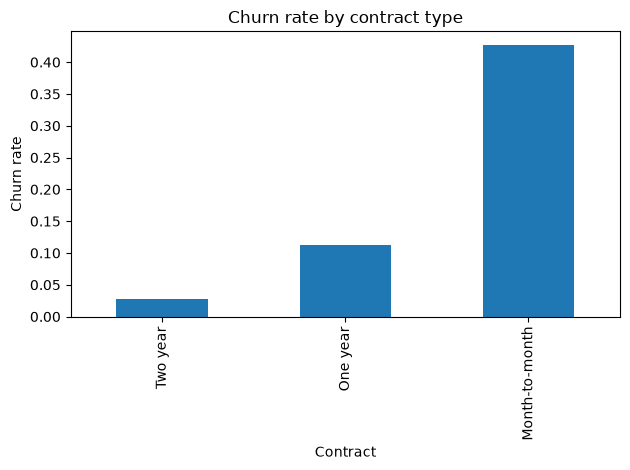

In [27]:
import matplotlib.pyplot as plt

rates = df.groupby("Contract")["Churn_flag"].mean().sort_values()
rates.plot(kind="bar")
plt.ylabel("Churn rate")
plt.title("Churn rate by contract type")
plt.tight_layout()
plt.show()

In [28]:
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


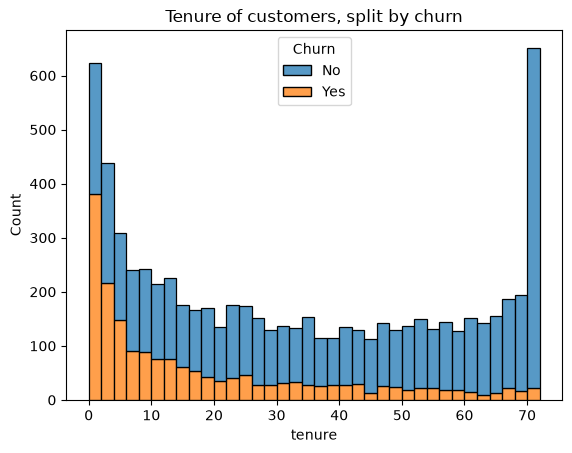

In [29]:
import seaborn as sns

sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack")
plt.title("Tenure of customers, split by churn")
plt.show()